In [1]:
import sys
import os

# 获取当前文件所在目录的路径
current_dir = os.path.dirname(os.path.abspath('__file__'))
# 获取上级目录的路径
parent_dir = os.path.abspath(os.path.join(current_dir, os.pardir))
# 将上级目录添加到 sys.path
sys.path.append(parent_dir)

import torch 
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from new_Main_PINN import PINN
from sklearn.model_selection import train_test_split

In [2]:
# 加载数据
file_path = 'Fatigue_life.csv'
df = pd.read_csv(file_path, usecols=[1, 3, 4], skiprows=1, header=None)
df.columns = ['S', 'lg10_N', 'T']
features = ['S', 'T']

# 分离特征和目标变量
X = df[['S', 'T']].values    
y = df['lg10_N'].values

# 标准化特征
scaler = StandardScaler()
X = scaler.fit_transform(X)
temperatures = np.unique(df['T'])  # 从数据集中读取唯一的T值

# 转换为 PyTorch 张量
X_tensor = torch.tensor(X, dtype=torch.float32)
X_tensor.requires_grad = True  # 确保是叶子变量并启用梯度
y = y.reshape(-1, 1)
y_tensor = torch.tensor(y, dtype=torch.float32)

In [3]:
best_architecture_path = 'bayesian_optimization_results_new.csv'

best_architecture = pd.read_csv(best_architecture_path)

# 找到目标值（target）最大的行
optimal_architecture = best_architecture.loc[best_architecture['target'].idxmax()]

# 打印最优架构
print("最优模型架构：")
print(optimal_architecture)

最优模型架构：
l2_lambda             0.000560
neurons_per_layer    20.000000
num_layers            1.000000
target               -0.005659
dropout_rate          0.300000
Name: 7, dtype: float64


In [4]:
# Read the Bayesian optimization results from the CSV file
best_architecture_path = 'bayesian_optimization_results_new.csv'
best_architecture = pd.read_csv(best_architecture_path)

# Find the row with the maximum target value (-MSE)
optimal_architecture = best_architecture.loc[best_architecture['target'].idxmax()]

# Map the actual number of layers and neurons per layer
num_layers = int(round(optimal_architecture['num_layers']))
neurons_per_layer_index = int(round(optimal_architecture['neurons_per_layer']))

# # Define the list of possible neuron counts for each layer
# neurons_per_layer_list = [5, 10, 15, 20, 25, 30]
# neurons_per_layer = neurons_per_layer_list[neurons_per_layer_index]

# Output the best model architecture
print("Best Model Architecture:")
print(f"Number of hidden layers: {num_layers}")
print(f"Number of neurons per layer: {neurons_per_layer_index}")
print(f"L2 regularization parameter: {optimal_architecture['l2_lambda']:.6f}")
print(f"dropout rate: {optimal_architecture['dropout_rate']:.6f}")
print(f"Negative MSE (target value): {optimal_architecture['target']:.6f}")

Best Model Architecture:
Number of hidden layers: 1
Number of neurons per layer: 20
L2 regularization parameter: 0.000560
dropout rate: 0.300000
Negative MSE (target value): -0.005659


In [5]:
best_grid_search_path = 'grid_search_results.csv'
best_grid_search = pd.read_csv(best_grid_search_path)

# Find the row with the maximum target value (-MSE)
optimal_grid_search = best_grid_search.loc[best_grid_search['mse'].idxmin()]

# Output the best model architecture
print("Best Model Architecture:")
print(f"Best physical weight: {optimal_grid_search['weight']}")
print(f'Best physical beta: {optimal_grid_search["beta"]}')


Best Model Architecture:
Best physical weight: 0.25
Best physical beta: 100.0


In [6]:
# spilt data
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.3, random_state=1)

In [7]:
other_constraints = {
    1: {'type': 'grad_sign', 'value': -1}  # 对温度变量施加一阶导数为-1的约束
}

# 定义 PINN 模型
input_size = X_tensor.shape[1]  # 输入维度（应为 2：应力和温度）
hidden_layer_sizes = [neurons_per_layer_index] * num_layers  # 隐藏层的大小
dropout_rate = optimal_architecture['dropout_rate']  # dropout rate
l2_lambda = optimal_architecture['l2_lambda']  # L2 正则化参数

PINN_model = PINN(input_size=input_size, hidden_layer_sizes=hidden_layer_sizes, stress_index=0, other_constraints=other_constraints, l2_lambda=l2_lambda, dropout_rate=dropout_rate)

# 训练参数
epochs = 10000
lr_adam = 0.005
lr_lbfgs = 0.01
weight = optimal_grid_search['weight']
beta = optimal_grid_search['beta']
switch_epoch = 10000

# 训练模型
print("Starting training...")
(PINN_loss_curve, PINN_R2_curve, PINN_data_loss_history,  
 PINN_phys_loss_S_history, PINN_phys_loss_SS_history, 
 PINN_other_phys_loss_history, PINN_individual_other_phys_losses_history,
 PINN_lg_N_S_grad, PINN_lg_N_SS_grad, PINN_other_grads) = PINN_model.optimize(
    X_train, y_train, epochs, lr_adam, lr_lbfgs, weight, beta, switch_epoch, physical_loss_type='G', return_final_derivatives=True)

Starting training...


In [8]:
# 评估模型
r2_test_PINN = PINN_model.evaluate(X_test, y_test)
r2_train_PINN = PINN_model.evaluate(X_train, y_train)
print(f"R^2 on test data: {r2_test_PINN:.4f}")
print(f"R^2 on train data: {r2_train_PINN:.4f}")

mse= nn.MSELoss()
mse_test_PINN = mse(PINN_model(X_test), y_test)
mse_train_PINN = mse(PINN_model(X_train), y_train)
print(f'mse test PINN: {mse_test_PINN:.4f}')
print(f'mse train PINN: {mse_train_PINN:.4f}')

# 预测
predictions_PINN = PINN_model.predict(X_tensor)
predictions_PINN = predictions_PINN.detach().numpy()

pre_PINN_train = PINN_model.predict(X_train)
pre_PINN_train = pre_PINN_train.detach().numpy()

pre_PINN_test = PINN_model.predict(X_test)
pre_PINN_test = pre_PINN_test.detach().numpy()

# 输出预测结果
print("Predicted log life:")
for i, pred in enumerate(predictions_PINN):
    print(f"Sample {i+1}: Predicted log life = {pred[0]:.6f}, Actual log life = {y[i][0]:.6f}")
    

R^2 on test data: 0.8255
R^2 on train data: 0.9054
mse test PINN: 0.0070
mse train PINN: 0.0052
Predicted log life:
Sample 1: Predicted log life = 4.913618, Actual log life = 4.950491
Sample 2: Predicted log life = 5.056244, Actual log life = 5.087519
Sample 3: Predicted log life = 5.056244, Actual log life = 5.096875
Sample 4: Predicted log life = 5.056244, Actual log life = 5.058141
Sample 5: Predicted log life = 5.056244, Actual log life = 5.000894
Sample 6: Predicted log life = 5.056244, Actual log life = 5.039537
Sample 7: Predicted log life = 5.056244, Actual log life = 5.112886
Sample 8: Predicted log life = 5.056244, Actual log life = 4.977961
Sample 9: Predicted log life = 5.187683, Actual log life = 5.234694
Sample 10: Predicted log life = 5.268107, Actual log life = 5.143212
Sample 11: Predicted log life = 5.268107, Actual log life = 5.230094
Sample 12: Predicted log life = 5.268107, Actual log life = 5.181926
Sample 13: Predicted log life = 5.268107, Actual log life = 5.148

# 解包

In [9]:
import csv
results_PINN = (PINN_loss_curve, PINN_R2_curve, PINN_data_loss_history, 
           PINN_phys_loss_S_history, PINN_phys_loss_SS_history, 
           PINN_other_phys_loss_history, PINN_individual_other_phys_losses_history,
           PINN_lg_N_S_grad, PINN_lg_N_SS_grad, PINN_other_grads)


PINN_loss_curve = results_PINN[0]
PINN_R2_curve = results_PINN[1]
PINN_data_loss_history = results_PINN[2]
PINN_phys_loss_S_history = results_PINN[3]
PINN_phys_loss_SS_history = results_PINN[4]
PINN_other_phys_loss_history = results_PINN[5]
PINN_individual_other_phys_losses_history = results_PINN[6]



In [10]:
#export the results to csv file
output_file = "new_PINN_results.csv"

with open(output_file, mode='w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    # Write the PINN results
    writer.writerow(["PINN Loss Curve", "PINN R^2 Curve", "PINN Data Loss History",
                     "PINN Physics Loss S History", "PINN Physics Loss SS History",
                     "PINN Other Physics Loss History", "PINN Individual Other Physics Losses History",
                     "PINN lg_N_S Grad", "PINN lg_N_SS Grad", "PINN Other Grads"])
    writer.writerow(results_PINN)

print(f"PINN results saved to {output_file}")


PINN results saved to new_PINN_results.csv


# plot

In [11]:
monet_colors = ['#FDBF6F', '#B2DF8A', '#A6CEE3', '#CAB2D6', '#FF7F00', '#6A3D9A']

plt.rcParams.update({'font.size': 20})

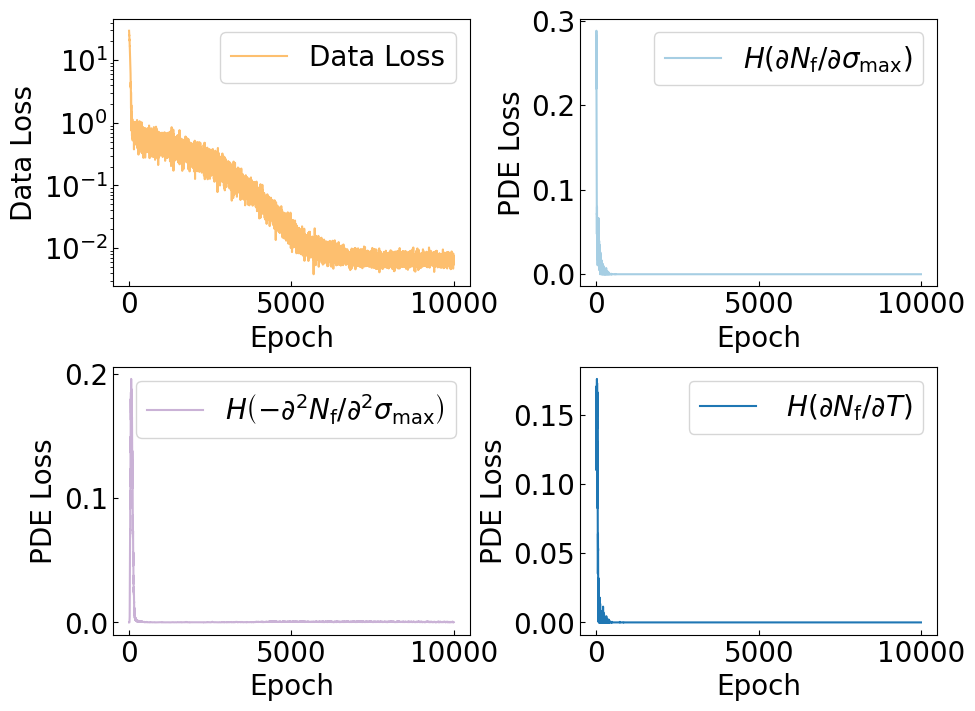

In [12]:
fig2, axis2 = plt.subplots(2, 2, figsize=(
    16*2/3, 8))  # 与第一个图的子图保持一致
fontsize = 20

# 确保每个子图宽高比为 3:4
for ax_row in axis2:
    for ax in ax_row:
        ax.set_box_aspect(3 / 4)

# 绘制数据损失曲线
axis2[0, 0].plot(PINN_data_loss_history, label='Data Loss', color='#FDBF6F')
axis2[0, 0].set_yscale('log')
axis2[0, 0].set_xlabel('Epoch', fontsize=fontsize)
axis2[0, 0].set_ylabel('Data Loss', fontsize=fontsize)
axis2[0, 0].tick_params(axis='both', direction='in', labelsize=fontsize)
axis2[0, 0].legend(fontsize=fontsize)

# 绘制物理损失 S 曲线
axis2[0, 1].plot(PINN_phys_loss_S_history, label=r'$H \left(\partial N_{\mathrm{f}}/ \partial \sigma_{\mathrm{max}}\right)$', color='#A6CEE3')
axis2[0, 1].set_xlabel('Epoch', fontsize=fontsize)
axis2[0, 1].set_ylabel('PDE Loss', fontsize=fontsize)
axis2[0, 1].tick_params(axis='both', direction='in', labelsize=fontsize)
axis2[0, 1].legend(fontsize=fontsize)

# 绘制物理损失 SS 曲线
axis2[1, 0].plot(PINN_phys_loss_SS_history, label=r'$H\left(- \partial^2 N_{\mathrm{f}} / \partial^2 \sigma_{\mathrm{max}}\right)$', color='#CAB2D6')
axis2[1, 0].set_xlabel('Epoch', fontsize=fontsize)
axis2[1, 0].set_ylabel('PDE Loss', fontsize=fontsize)
axis2[1, 0].tick_params(axis='both', direction='in', labelsize=fontsize)
axis2[1, 0].legend(fontsize=fontsize)
# axis2[1, 0].set_yscale('log')

# 绘制其他物理损失曲线
for i, (constraint_idx, loss_history) in enumerate(PINN_individual_other_phys_losses_history.items()):
    axis2[1, 1].plot(loss_history, label=r' $H\left(\partial N_{\mathrm{f}} / \partial T\right)$', color=f'C{i}')
axis2[1, 1].set_xlabel('Epoch', fontsize=fontsize)
axis2[1, 1].set_ylabel('PDE Loss', fontsize=fontsize)
axis2[1, 1].tick_params(axis='both', direction='in', labelsize=fontsize)
axis2[1, 1].legend(fontsize=fontsize)

# 调整布局并保存
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.savefig('new_plot/loss_curve.svg', dpi=600, bbox_inches='tight')
plt.show()


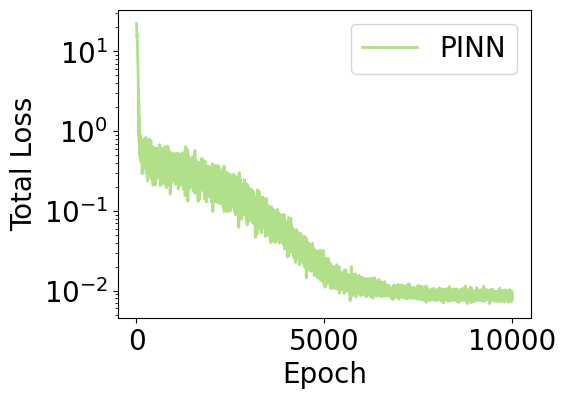

In [13]:
plt.figure(figsize=(16*1/3, 4))
plt.plot(PINN_loss_curve, label='PINN', color=monet_colors[1], linewidth=2)
# plt.plot(PINN_data_loss_history, label='PINN', color=monet_colors[2], linewidth=2)
plt.yscale('log')
plt.xlabel('Epoch', fontsize=fontsize)
plt.ylabel('Total Loss', fontsize=fontsize)
plt.legend(fontsize=fontsize)
# plt.savefig('new_plot/total_loss_curve_fixed.svg', dpi=600, bbox_inches='tight')
plt.show()